# Uber Pick-ups in New York City (2014-2015)

In this project I will analyze Uber pick-ups in New York city, using data that is from April - September of 2014, and January - June of 2015. I will analyze which month and day have the most trips, what are the rush hours of Uber, perform a Pareto analysis, determine rides to airport demand, as well as demand by location.

## Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import folium
from folium.plugins import HeatMapWithTime

## Data and clean-up

In [3]:
from pathlib import Path

project_path = Path.cwd()

folder_path = project_path / "Datasets"

files = folder_path.glob("*.csv")

tables = {}

for file in files:
    file_name = file.stem
    tables[file_name] = pd.read_csv(file, encoding="cp1252")

print(f"Uploaded {len(tables)} files")


Uploaded 7 files


In [4]:
uber15 = tables["uber-raw-data-janjune-15_sample"]
uber15

,Dispatching_base_num,Pickup_date,Affiliated_base_num,locationID
0,B02617,2015-05-02 21:43:00,B02764,237
1,B02682,2015-01-20 19:52:59,B02682,231
2,B02617,2015-03-19 20:26:00,B02617,161
3,B02764,2015-04-10 17:38:00,B02764,107
4,B02764,2015-03-23 07:03:00,B00111,140
...,...,...,...,...
99995,B02764,2015-04-13 16:12:00,B02764,234
99996,B02764,2015-03-06 21:32:00,B02764,24
99997,B02598,2015-03-19 19:56:00,B02598,17
99998,B02682,2015-05-02 16:02:00,B02682,68


In [5]:
uber15 = uber15.drop_duplicates()

uber15["Pickup_date"] = pd.to_datetime(uber15["Pickup_date"])

## Analysis

#### Determining which month and day of the week have the most Uber pick-ups

In [6]:
uber15["month"] = uber15["Pickup_date"].dt.month_name()
uber15["day"] = uber15["Pickup_date"].dt.day_name()

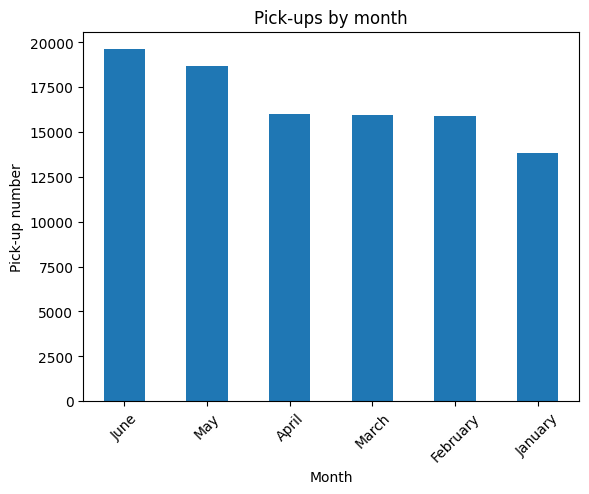

In [7]:
uber15["month"].value_counts().plot(kind="bar")

plt.title('Pick-ups by month')
plt.xlabel('Month')
plt.ylabel('Pick-up number')
plt.xticks(rotation=45)
plt.show()

June is the month with the most Uber pick-ups in New York city.

In [8]:
pivot = pd.crosstab(index= uber15["month"], columns= uber15["day"])

pivot

day,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
month,,,,,,,
April,2365,1833,2508,2052,2823,1880,2521
February,2655,1970,2550,2183,2396,2129,2013
January,2508,1353,2745,1651,2378,1444,1740
June,2793,2848,3037,2485,2767,3187,2503
March,2465,2115,2522,2379,2093,2388,2007
May,3262,1865,3519,2944,2627,2115,2328


In [9]:
month_order = ["January", "February", "March", "April", "May", "June"]
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot_sorted = pivot.reindex(index=month_order).reindex(columns=day_order)

pivot_sorted

day,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
month,,,,,,,
January,1353,1444,1740,2378,2508,2745,1651
February,1970,2129,2013,2396,2655,2550,2183
March,2115,2388,2007,2093,2465,2522,2379
April,1833,1880,2521,2823,2365,2508,2052
May,1865,2115,2328,2627,3262,3519,2944
June,2848,3187,2503,2767,2793,3037,2485


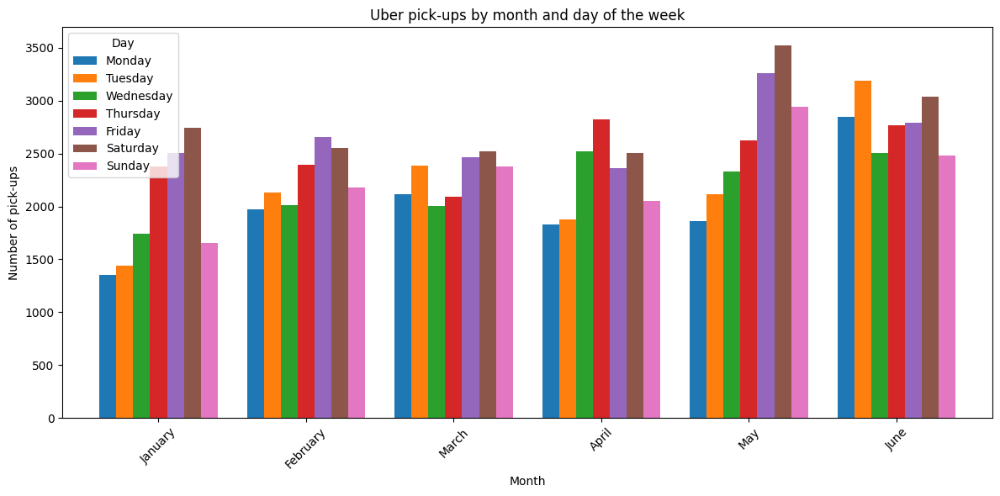

In [10]:
pivot_sorted.plot(kind="bar", figsize=(12, 6), width=0.8)

plt.title("Uber pick-ups by month and day of the week")
plt.xlabel("Month")
plt.ylabel("Number of pick-ups")
plt.legend(title="Day")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Across all months with a couple of exceptions the days of the week with the most Uber pick-ups are Friday and Saturday, with overall most pick-ups being on Saturdays of May, and Mondays generally being the least popular day of the week.

#### Determining New York Uber rush hours by day of the week

In [11]:
uber15["hour"] = uber15["Pickup_date"].dt.hour

hourly_rush = uber15.groupby(["day", "hour"], as_index=False).size()

hourly_rush

,day,hour,size
0,Friday,0,581
1,Friday,1,333
2,Friday,2,197
3,Friday,3,138
4,Friday,4,161
...,...,...,...
163,Wednesday,19,1044
164,Wednesday,20,897
165,Wednesday,21,949
166,Wednesday,22,900


In [12]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

hourly_rush["day"] = pd.Categorical(hourly_rush["day"], categories=day_order, ordered=True)

hourly_rush = hourly_rush.sort_values(["day", "hour"])

hourly_rush

,day,hour,size
24,Monday,0,339
25,Monday,1,178
26,Monday,2,109
27,Monday,3,100
28,Monday,4,139
...,...,...,...
91,Sunday,19,711
92,Sunday,20,697
93,Sunday,21,615
94,Sunday,22,658


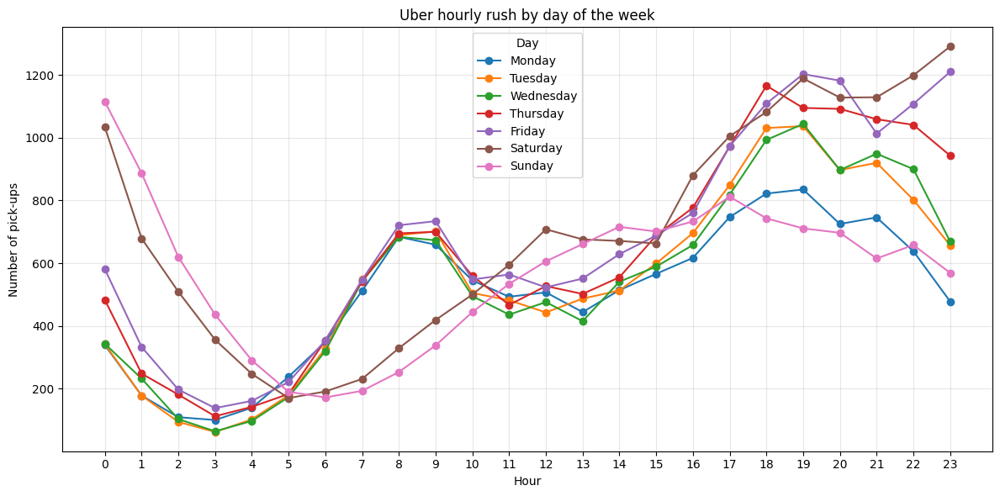

In [13]:
plt.figure(figsize=(12, 6))

for day in hourly_rush["day"].unique():
    day_data = hourly_rush[hourly_rush["day"] == day]

    plt.plot(day_data["hour"], day_data["size"], marker="o", label=day)

plt.title("Uber hourly rush by day of the week")
plt.xlabel("Hour")
plt.ylabel("Number of pick-ups")
plt.legend(title="Day")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In New York Uber is the busiest on weekend nights, specifically the nights between Friday and Saturday, as well as Saturday and Sunday. The least busy time is 3 AM on weekdays.

#### Pareto analysis

In [14]:
base_df = uber15["Dispatching_base_num"].value_counts().reset_index()

base_df.columns = ["Base", "Trips"]
base_df

,Base,Trips
0,B02764,40267
1,B02682,24460
2,B02617,14496
3,B02598,10644
4,B02765,8120
5,B02512,1757
6,B02835,193
7,B02836,9


In [15]:
base_df["Trip_percentage"] = (base_df["Trips"]/base_df["Trips"].sum())*100

base_df["Cumulative_percentage"] = (base_df["Trips"].cumsum() / base_df["Trips"].sum()) * 100

base_df

,Base,Trips,Trip_percentage,Cumulative_percentage
0,B02764,40267,40.288756,40.288756
1,B02682,24460,24.473216,64.761971
2,B02617,14496,14.503832,79.265804
3,B02598,10644,10.649751,89.915554
4,B02765,8120,8.124387,98.039942
5,B02512,1757,1.757949,99.797891
6,B02835,193,0.193104,99.990995
7,B02836,9,0.009005,100.000000


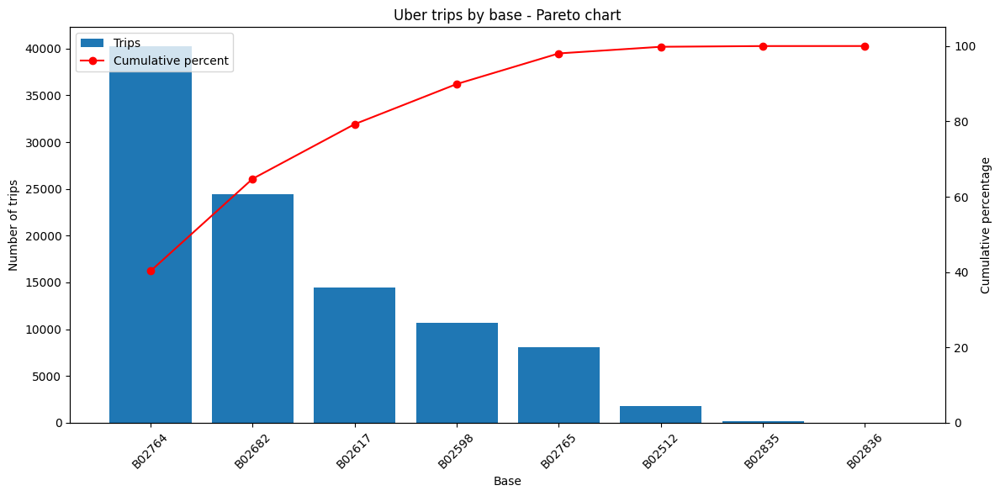

In [16]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(base_df["Base"], base_df["Trips"], label="Trips")
ax1.set_xlabel("Base")
ax1.set_ylabel("Number of trips")
ax1.tick_params(axis="x", rotation=45)


ax2 = ax1.twinx()

ax2.plot(base_df["Base"], base_df["Cumulative_percentage"], color="red", marker="o", label="Cumulative percent")
ax2.set_ylabel("Cumulative percentage")
ax2.set_ylim(0, 105)


lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Uber trips by base - Pareto chart")
plt.tight_layout()
plt.show()

Three main bases are responsible for 80% of the Uber trips in New York city.

#### Airport demand analysis

In [17]:
airport_ids = [1, 132, 138]

airport_df = uber15[uber15["locationID"].isin(airport_ids)]

In [18]:
airport_map = {1: "EWR", 132: "JFK", 138: "LGA"}

airport_df["airport_name"] = airport_df["locationID"].map(airport_map)

In [19]:
airport_df["hour"] = airport_df["Pickup_date"].dt.hour

In [20]:
airport_hourly = airport_df.groupby(["airport_name", "hour"]).size().reset_index(name="trips")

airport_hourly.head(10)

,airport_name,hour,trips
0,JFK,0,129
1,JFK,1,46
2,JFK,2,17
3,JFK,3,4
4,JFK,4,7
5,JFK,5,44
6,JFK,6,99
7,JFK,7,70
8,JFK,8,69
9,JFK,9,31


In [21]:
airport_pivot = airport_hourly.pivot(index="hour", columns="airport_name", values="trips").fillna(0)
airport_pivot = airport_pivot.sort_index()

airport_pivot

airport_name,JFK,LGA
hour,,
0,129.0,51.0
1,46.0,7.0
2,17.0,7.0
3,4.0,1.0
4,7.0,0.0
5,44.0,6.0
6,99.0,1.0
7,70.0,24.0
8,69.0,52.0


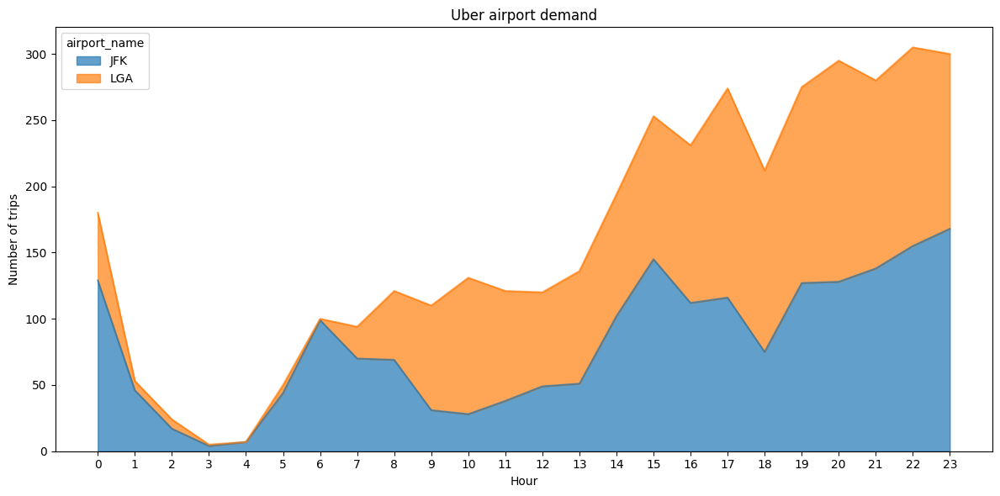

In [22]:
airport_pivot.plot(kind="area", figsize=(12, 6), stacked=True, alpha=0.7)

plt.title("Uber airport demand")
plt.xlabel("Hour")
plt.ylabel("Number of trips")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

Both airports have similar demand, other than JFK being significantly more popular between midnight and 6 AM. Peak hours are from 3 PM to 11 PM, and the least busy time is between 2 AM and 5 AM.

#### Determining Uber demand by location

In [23]:
uber_files_list = [tables["uber-raw-data-apr14"],
                   tables["uber-raw-data-may14"], 
                   tables["uber-raw-data-jun14"], 
                   tables["uber-raw-data-jul14"], 
                   tables["uber-raw-data-aug14"], 
                   tables["uber-raw-data-sep14"]]

uber_files = pd.concat(uber_files_list, ignore_index=True)

uber_files.drop_duplicates(inplace=True)

uber_files

,Date/Time,Lat,Lon,Base
0,4/1/2014 0:11:00,40.7690,-73.9549,B02512
1,4/1/2014 0:17:00,40.7267,-74.0345,B02512
2,4/1/2014 0:21:00,40.7316,-73.9873,B02512
3,4/1/2014 0:28:00,40.7588,-73.9776,B02512
4,4/1/2014 0:33:00,40.7594,-73.9722,B02512
...,...,...,...,...
4534322,9/30/2014 22:57:00,40.7668,-73.9845,B02764
4534323,9/30/2014 22:57:00,40.6911,-74.1773,B02764
4534324,9/30/2014 22:58:00,40.8519,-73.9319,B02764
4534325,9/30/2014 22:58:00,40.7081,-74.0066,B02764


In [24]:
uber_files["datetime"] = pd.to_datetime(uber_files["Date/Time"])

uber_files["hour"] = uber_files["datetime"].dt.hour

In [25]:
hourly_data = []

for h in range(24):
    temp = uber_files[uber_files["hour"] == h][["Lat", "Lon"]]
    hourly_data.append(temp.values.tolist())

In [26]:
map = folium.Map(location=[40.7128, -74.0060], zoom_start=11)

HeatMapWithTime(hourly_data, radius=9, auto_play=False, max_opacity=0.8).add_to(map)

map

The demand for Uber in New York city throughout the day is the highest in Manhattan and Brooklyn areas